# From a recording to a checked passage

On tick 6 a player has a blue key. On tick 19 the same player exits. How could a reader determine that every intervening input is possible? Work through a recorded example, change an input, and inspect what the Lean kernel accepts.

**To run the lab**, open this notebook with a Jupyter Python 3 kernel. The last two executable cells call stock Lean 4.33.0 through elan. Install that edition with `elan toolchain install leanprover/lean4:v4.33.0` before running them. All images and both Lean files are embedded in the download. The Python examples use the standard library. [Download this notebook](passage-lab.ipynb) · [Read the historical chapter](index.html) · [Install Lean](https://lean-lang.org/install/) · [Notebook format](https://nbformat.readthedocs.io/en/latest/format_description.html)

## Look through the native Lean camera

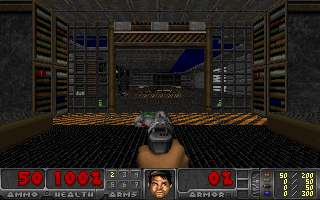

This 320 × 200 image comes from the native CombatV2 map worker on a WMI compute node. The engine loads the level and renders the camera from ordinary spawn. The data and artwork here belong to Freedoom: Phase 1. The Hangar theorem later in this notebook uses a different, precisely identified commercial map foundation. Loading the same slot label E1M1 with different bytes produces a different scene. [Native player and worker source](../game/native.html) · [Freedoom project](https://freedoom.github.io/) · [Artwork license](freedoom-COPYING.txt)

## Read a real controller

These two screenshots come from the released public ProofGrid course L01 in its direct-route playback. The right pane renders original raycast scenery. The left pane follows the current input through the course’s Lean source. Both images are captures from the running browser. Use the slider to inspect other ticks. [Open at tick 6](../game/index.html?level=L01&route=direct&tick=6) · [Open at tick 19](../game/index.html?level=L01&route=direct&tick=19)

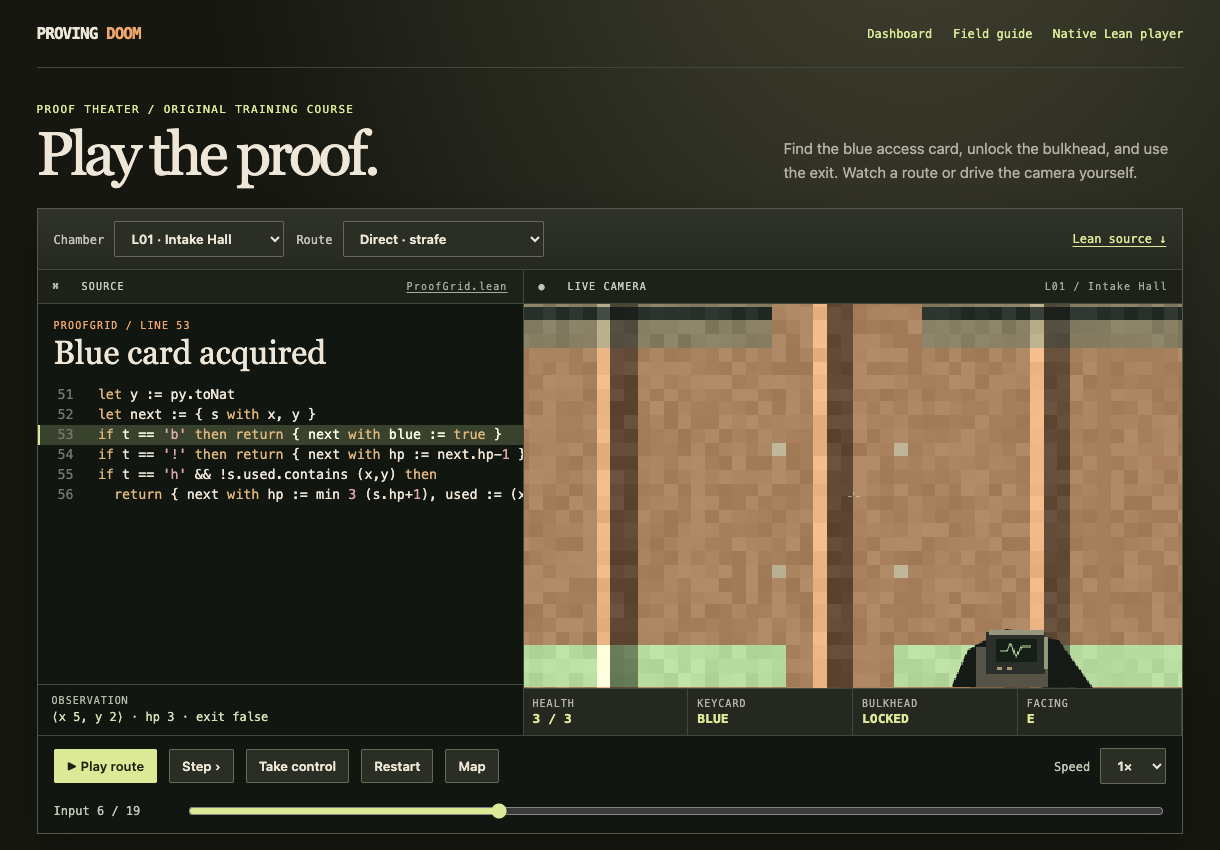

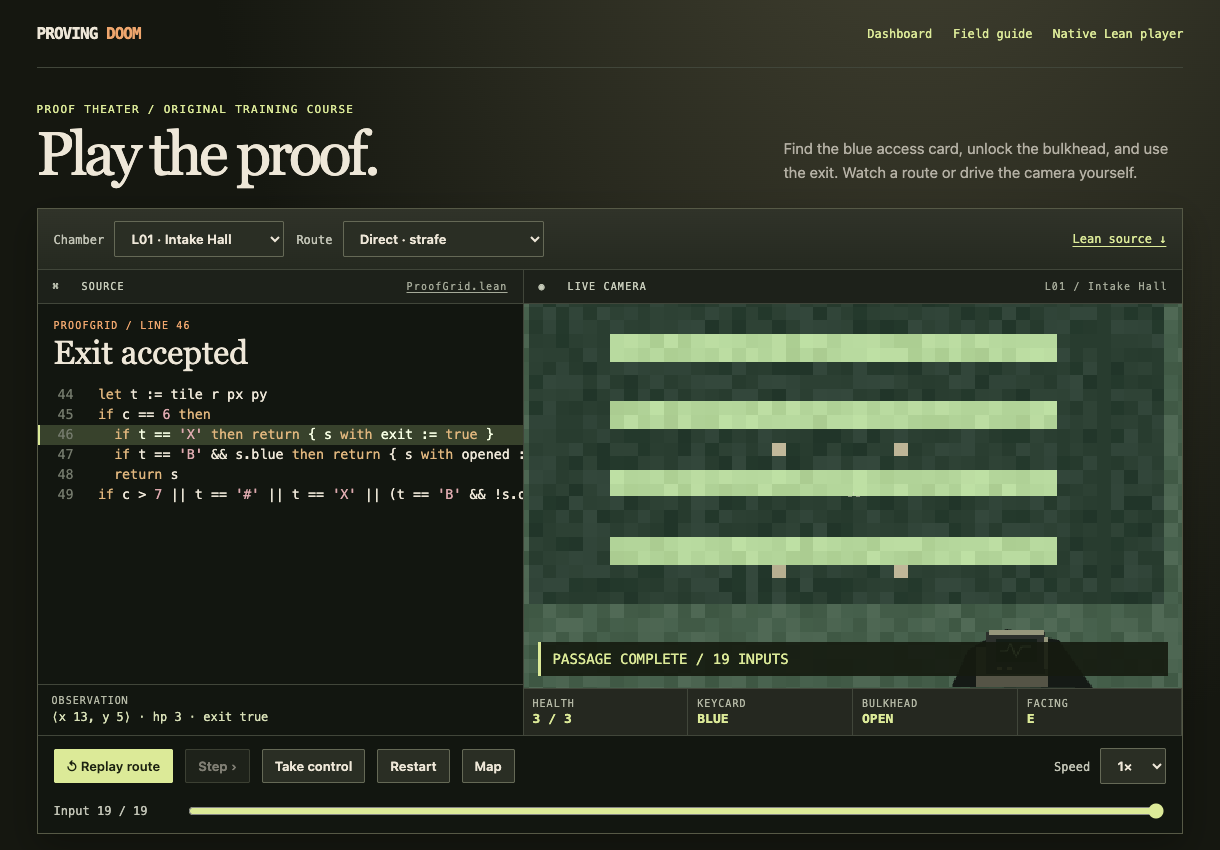

The course and the historical CombatV2 runs have different transition functions and maps. To locate a claim, ask which function the theorem mentions, where its initial state comes from, and what the exit flag means. Alaska Hoffman’s (Lean)DOOM translates original-format level data into a native Lean game. The research edition introduced specified enemy arithmetic and a terminating weapon controller to make its transitions reducible in proofs. Equivalence to the upstream enemy program remains open. [Course model](../game/ProofGrid.lean) · [Pinned upstream engine](https://github.com/alaskahoffman/leandoom/tree/dd795d67c075b3c3d1149494ddec6aff756e2a64) · [Engine and proof chapter](index.html#engines)

## Define an airlock small enough to audit

A *state* contains information that influences future steps. The lesson's entire state is one of four phases. Collecting the key at the dock changes the phase to carrying. Using it while carrying opens the door. Walking after the door opens leads outside. Every remaining state–input pair leaves the phase unchanged, including firing and waiting. Once outside, the model stays outside. This intentionally small airlock is a separate mechanism.

Let $T(s,k)$ be one step. Given inputs $k_1,\ldots,k_n$, set $s_0=\mathrm{dock}$ and $s_{i+1}=T(s_i,k_{i+1})$. A tape with $n$ inputs visits $n+1$ states. The Python cell mirrors the three advancing cases so we can interrogate them before reading the independent Lean definitions. [Algebraic data types and pattern matching](https://lean-lang.org/functional_programming_in_lean/) · [Small-step semantics](https://softwarefoundations.cis.upenn.edu/plf-current/Smallstep.html)

In [1]:
from itertools import product

keys = ("collect", "use", "walk", "wait", "fire")
advances = {("dock", "collect"): "carrying", ("carrying", "use"): "opened",
            ("opened", "walk"): "outside"}

def step(state, key):
    if key not in keys:
        raise ValueError("Unknown key")
    return advances.get((state, key), state)

def states(tape, start="dock"):
    path = [start]
    for key in tape:
        path.append(step(path[-1], key))
    return path

def first_exit(tape):
    path = states(tape)
    return path[-1] == "outside" and "outside" not in path[:-1]

route = ("collect", "use", "walk")
wrong = ("use", "collect", "walk")
late = route + ("wait",)
for tape in [route, wrong, late]:
    print(" / ".join(tape), "=>", " / ".join(states(tape)), "| first exit:", first_exit(tape))
assert first_exit(route) and not first_exit(wrong) and not first_exit(late)

collect / use / walk => dock / carrying / opened / outside | first exit: True
use / collect / walk => dock / dock / carrying / carrying | first exit: False
collect / use / walk / wait => dock / carrying / opened / outside / outside | first exit: False


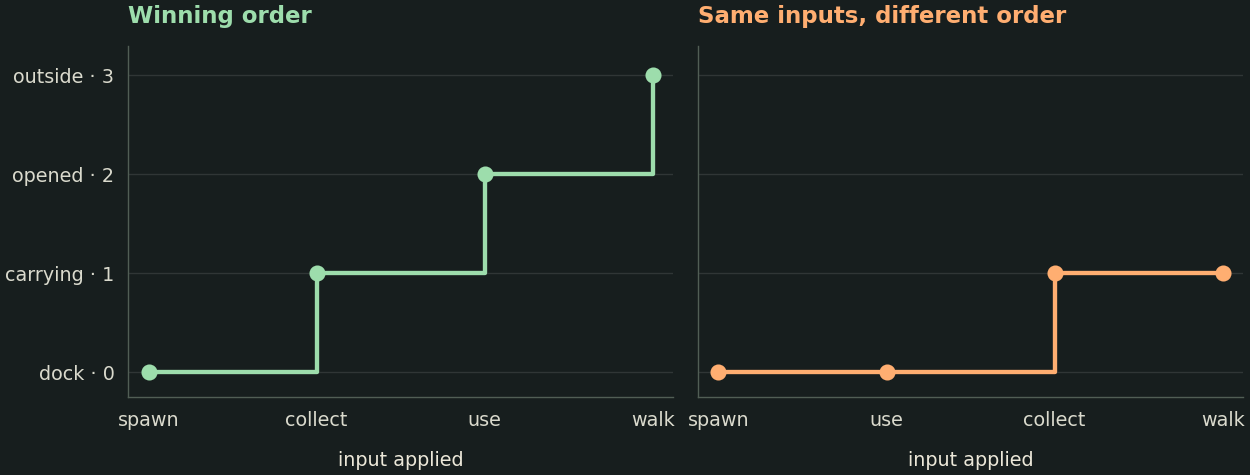

Why does the third tape above fail the *first*-exit test? It finishes outside, but its proper prefix already finishes outside. An endpoint statement alone would accept it. A history-sensitive proposition examines prefixes. A full CombatV2 passage can additionally require that every intermediate state has positive health and no physics error. [Research declarations](records.html#e1m2) · [Quantifiers and equality](https://lean-lang.org/theorem_proving_in_lean4/quantifiers_and_equality.html)

<a id="shortest"></a>

## Count short controllers, then prove a bound

If a three-input witness works, it gives an upper bound on the optimum. To obtain a lower bound, first exhaust all tapes of length less than three. The next cell counts exactly $1+5+5^2=31$ tapes in these shorter layers. Try changing the transition table to add a new shortcut and re-running the assertions. [Finite enumeration in Python](https://docs.python.org/3/library/itertools.html#itertools.product)

In [2]:
winners = {}
for length in range(4):
    winners[length] = [t for t in product(keys, repeat=length) if first_exit(t)]
    print(f"length {length}: {len(winners[length])} first exits among {len(keys) ** length} tapes")
assert all(not winners[length] for length in range(3))
assert winners[3] == [route]
print("Shortest tape:", " / ".join(winners[3][0]))

length 0: 0 first exits among 1 tapes
length 1: 0 first exits among 5 tapes
length 2: 0 first exits among 25 tapes
length 3: 1 first exits among 125 tapes
Shortest tape: collect / use / walk


**Claim.** Every tape $K$ that reaches the outside from the dock has $|K|\ge3$, including tapes that wait after exiting.

1. Assign ranks $r(\mathrm{dock})=0$, $r(\mathrm{carrying})=1$, $r(\mathrm{opened})=2$, $r(\mathrm{outside})=3$.
2. Inspect one input in each phase. Every transition either stays put or advances by one, so $r(T(s,k))\le r(s)+1$.
3. Induct on the list. In the empty case the state is unchanged. In the cons case apply the induction hypothesis to the tail **from the updated starting state**. Then apply step 2 to its head. Thus $r(R(s,K))\le r(s)+|K|$ where $R$ executes the entire tape.
4. Substitute a winning endpoint and the dock's rank. This gives $3\le |K|$. The winning tape has length three and fires zero shots. Together with nonnegativity, that also determines this model’s minimum firing count.

This rank argument works over arbitrarily long input lists. The finite search above checks all shorter competitors in the particular airlock. The Lean proofs named `runBound` and `minimumLength` implement steps 3 and 4. [Induction in Lean](https://lean-lang.org/theorem_proving_in_lean4/induction_and_recursion.html) · [Lamport’s structured proofs](https://lamport.azurewebsites.net/pubs/proof.pdf)

## What a screenshot forgets

At the join between two segments, the second segment expects the first segment’s *complete* ending state. Suppose a more detailed state stores a player tile and whether the player holds a key. An observer who displays only the tile can miss a future change in reachability. The following counterexample uses a new, two-field model. [Semantic preservation and observations](https://compcert.org/man/manual001.html)

In [3]:
from typing import NamedTuple

class Frame(NamedTuple):
    tile: str
    blue_key: bool

def unlock(frame):
    return "exit" if frame.tile == "door" and frame.blue_key else frame.tile

left, right = Frame("door", True), Frame("door", False)
assert left.tile == right.tile and unlock(left) != unlock(right)
print("Same displayed tile:", left.tile)
print("Use with the key:", unlock(left), "| Use without the key:", unlock(right))

for cut in range(len(route) + 1):
    prefix, suffix = route[:cut], route[cut:]
    middle = states(prefix)[-1]
    assert states(suffix, middle)[-1] == states(route)[-1]
    print(f"Cut {cut}: restart the suffix from {middle}")

Same displayed tile: door
Use with the key: exit | Use without the key: door
Cut 0: restart the suffix from dock
Cut 1: restart the suffix from carrying
Cut 2: restart the suffix from opened
Cut 3: restart the suffix from outside


## Relate the exercise to real level certificates

Consider two stock-kernel zero-shot witnesses for Hangar in CombatV2. Replacing the 993-input witness by the 978-input witness improves an **upper** bound by 15. Nuclear Plant has a complete armed 1,017-input witness and its ordinary spawn is not an exit. In a surviving, error-free passage one must account for all 1,018 states including the start. The main suffix of that witness contains 998 ticks with 65 ordered actor slots per tick. These counts illustrate the work inside a particular certificate. [Hangar evidence](records.html#e1m1) · [Nuclear Plant evidence](records.html#e1m2)

Computer Station’s first checked collision move collects a clip, taking ammunition from 50 to 60, and relinks the player to the spatial lists for sector 60 and blockmap cell 846. Omitting the relink can change the next collision query. A separate compiler-assisted proof follows all 4,161 inputs to the exit with 45 health and 25 armor. Its imported `Recording.passage` declaration lists a generated native-decision axiom. [First-move proof](records.html#e1m7) · [Compiler-assisted passage audit](../downloads/combat-runs.json)

On 11 November 2026 an early Military Base tape collected yellow at input 126, red at 933 and blue at 1,664. At input 2,179 its extension tried a platform switch that the frozen CombatV2 engine leaves unimplemented. A later tape gathers the same three keys and crosses the unraised trench by strafe-running. It first exits at tick 1,917 with 27 health. What observation distinguishes a missing rule from an unreachable exit? Compare the unsuccessful switch activation with the successful landing in the proof viewer. [Earlier switch study](../evidence/e1m9/result.json) · [Watch Military Base](https://nasqret.github.io/leandoom-proofs/theater/?level=E1M9)

All nine original shareware maps have a checked passage from an independent ordinary spawn. In the Theater two routes have stock-kernel passage proofs and seven use compiler-assisted evaluation. Each film names its engine edition. An uninterrupted episode would need a theorem about the state carried from each exit to the next spawn. [Current original-map Proof Theater](https://nasqret.github.io/leandoom-proofs/theater/) · [Level evidence atlas](https://nasqret.github.io/leandoom-proofs/evidence/)

In [4]:
old_hangar, new_hangar = 993, 978
plant_inputs, plant_split, plant_slots = 1017, 19, 65
print("Hangar upper bound improved by", old_hangar - new_hangar, "inputs")
print("Nuclear Plant prefix states:", plant_inputs + 1)
print("Actor-slot updates in the Nuclear Plant suffix:", (plant_inputs - plant_split) * plant_slots)

Hangar upper bound improved by 15 inputs
Nuclear Plant prefix states: 1018
Actor-slot updates in the Nuclear Plant suffix: 64870


## Give the exact source to Lean

The next cell holds the complete Lean module that implements the airlock. `DecidableEq` supplies equality decisions. In the concrete theorems, `by decide` builds evidence for a closed proposition. The universal theorems use case analysis, induction and integer arithmetic. In `runAppend`, the induction hypothesis accepts the state reached after the head command. That is what makes the lemma reusable at an arbitrary checkpoint. A SHA-256 digest lets you check that the program bytes match the version used in the classroom run. [Lean tactics and computation](https://lean-lang.org/theorem_proving_in_lean4/axioms_and_computation.html) · [Audited source download](PassageLab.lean) · [Hash standard](https://csrc.nist.gov/pubs/fips/180-4/upd1/final)

In [5]:
from hashlib import sha256

lean_source = """import Std

namespace PassageLab

inductive Phase where
  | dock | carrying | opened | outside
  deriving DecidableEq, Repr

inductive Key where
  | collect | use | walk | wait | fire
  deriving DecidableEq, BEq, Repr

def step : Phase → Key → Phase
  | .dock, .collect => .carrying
  | .carrying, .use => .opened
  | .opened, .walk => .outside
  | s, _ => s

def run (s : Phase) : List Key → Phase
  | [] => s
  | k :: ks => run (step s k) ks

def states (s : Phase) : List Key → List Phase
  | [] => [s]
  | k :: ks => s :: states (step s k) ks

def rank : Phase → Nat
  | .dock => 0
  | .carrying => 1
  | .opened => 2
  | .outside => 3

def route : List Key := [.collect, .use, .walk]

theorem passage : run .dock route = .outside := by decide

theorem checkedStates :
    states .dock route = [.dock, .carrying, .opened, .outside] := by decide

theorem noFire : route.count .fire = 0 := by decide

theorem stepBound (s : Phase) (k : Key) : rank (step s k) ≤ rank s + 1 := by
  cases s <;> cases k <;> decide

theorem runBound (s : Phase) (ks : List Key) :
    rank (run s ks) ≤ rank s + ks.length := by
  induction ks generalizing s with
  | nil => simp [run]
  | cons k ks ih =>
    have tailBound := ih (step s k)
    have headBound := stepBound s k
    simp only [run, List.length_cons]
    omega

theorem minimumLength {ks : List Key} (wins : run .dock ks = .outside) :
    3 ≤ ks.length := by
  have h := runBound .dock ks
  rw [wins] at h
  simpa [rank] using h

theorem runAppend (s : Phase) (u v : List Key) :
    run s (u ++ v) = run (run s u) v := by
  induction u generalizing s with
  | nil => rfl
  | cons k ks ih => exact ih (step s k)

end PassageLab
"""
assert sha256(lean_source.encode()).hexdigest() == "a2dd14664fbf276c425f87c1322355d7be7589e3aca2e4ae4aa86088e6f5598f"
print("PassageLab.lean SHA-256:", sha256(lean_source.encode()).hexdigest())

PassageLab.lean SHA-256: a2dd14664fbf276c425f87c1322355d7be7589e3aca2e4ae4aa86088e6f5598f


## Compile the witness and audit its imports

This cell launches the stock compiler, writes an object module and then starts a **fresh Lean process** to import the module and ask which axioms its seven declarations use. The reports below come directly from that second process. A report listing `propext` records Lean’s propositional extensionality principle. An added placeholder such as `sorryAx` would change the report. The source, toolchain and the reported dependencies belong to the interpretation of the result. [Validating a Lean proof](https://lean-lang.org/doc/reference/latest/ValidatingProofs/) · [Download the audit commands](Audit.lean)

In [6]:
audit_source = """import PassageLab
#print axioms PassageLab.passage
#print axioms PassageLab.checkedStates
#print axioms PassageLab.noFire
#print axioms PassageLab.stepBound
#print axioms PassageLab.runBound
#print axioms PassageLab.minimumLength
#print axioms PassageLab.runAppend
"""
import os
import shutil
import subprocess
import tempfile
from pathlib import Path

def invoke(directory, *args):
    elan = shutil.which("elan")
    if elan is None:
        raise RuntimeError("Install elan and leanprover/lean4:v4.33.0 to run this cell.")
    env = dict(os.environ, LEAN_PATH=str(directory), LEAN_NUM_THREADS="1")
    return subprocess.run([elan, "run", "leanprover/lean4:v4.33.0", "lean", *args],
                          cwd=directory, capture_output=True, text=True, timeout=90, env=env)

with tempfile.TemporaryDirectory() as temporary:
    directory = Path(temporary)
    (directory / "PassageLab.lean").write_text(lean_source, encoding="utf-8")
    (directory / "Audit.lean").write_text(audit_source, encoding="utf-8")
    version = invoke(directory, "--version")
    version.check_returncode()
    print(version.stdout.strip())
    built = invoke(directory, "-DwarningAsError=true", "-o", "PassageLab.olean", "PassageLab.lean")
    assert built.returncode == 0, built.stdout + built.stderr
    imported = invoke(directory, "-DwarningAsError=true", "Audit.lean")
    assert imported.returncode == 0, imported.stdout + imported.stderr
    report = imported.stdout.strip()
    assert len(report.splitlines()) == 7 and "sorryAx" not in report
    print(report)

Lean (version 4.33.0, x86_64-unknown-linux-gnu, commit d8b18978322de05a8f3dba51ef03cf5461676c17, Release)


'PassageLab.passage' depends on axioms: [propext]
'PassageLab.checkedStates' depends on axioms: [propext]
'PassageLab.noFire' does not depend on any axioms
'PassageLab.stepBound' depends on axioms: [propext]
'PassageLab.runBound' depends on axioms: [propext, Quot.sound]
'PassageLab.minimumLength' depends on axioms: [propext, Quot.sound]
'PassageLab.runAppend' depends on axioms: [propext]


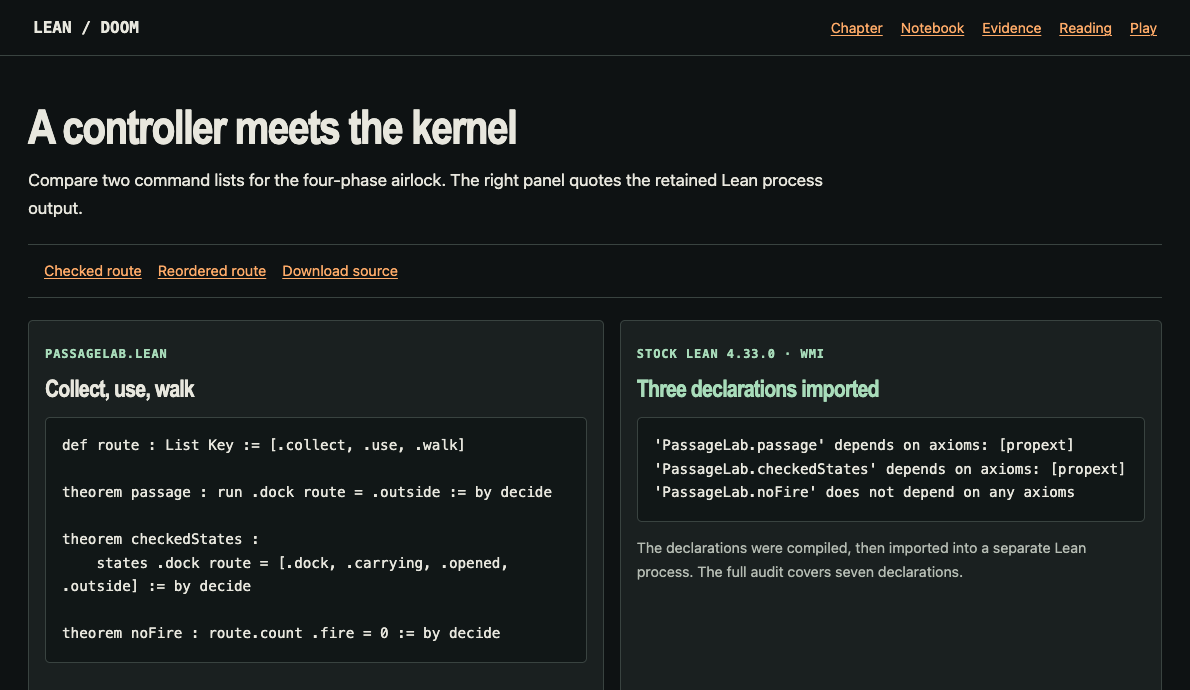

## Break the proof deliberately

Swap the first two controls and keep the original passage claim. A correct check now rejects it because the door stays closed when walk is pressed. We also test that the diagnostic names the failed goal, so a missing compiler cannot masquerade as a successful negative control. [Compare both transcripts](kernel.html) · [Raw rejection](wrong-order.txt)

In [7]:
before, after = "[.collect, .use, .walk]", "[.use, .collect, .walk]"
assert lean_source.count(before) == 1
with tempfile.TemporaryDirectory() as temporary:
    directory = Path(temporary)
    (directory / "WrongOrder.lean").write_text(lean_source.replace(before, after), encoding="utf-8")
    rejected = invoke(directory, "-DwarningAsError=true", "WrongOrder.lean")
    diagnostic = rejected.stdout + rejected.stderr
    assert rejected.returncode != 0 and "run Phase.dock route = Phase.outside" in diagnostic
    assert "is false" in diagnostic
    print(diagnostic.strip())

WrongOrder.lean:35:51: error: Tactic `decide` proved that the proposition
  run Phase.dock route = Phase.outside
is false
WrongOrder.lean:38:69: error: Tactic `decide` proved that the proposition
  states Phase.dock route = [Phase.dock, Phase.carrying, Phase.opened, Phase.outside]
is false


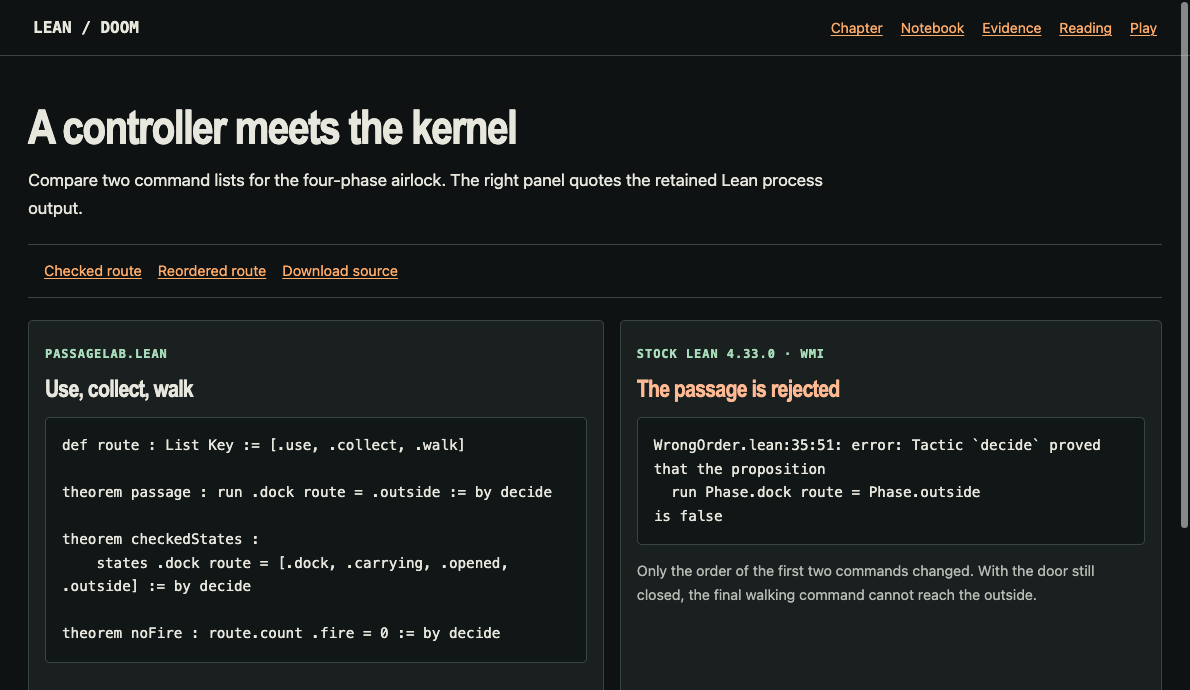

## Investigate a new controller

1. Change `route` to `collect, wait, use, walk` in the Python examples. Why do the endpoint and first-exit assertions survive while the claim of minimal length for *this* tape fails?
2. Add an emergency input that can skip two phases. Find a concrete counterexample to `stepBound`. Propose a lower bound that still holds, and say where to change the induction.
3. Define `safe` as positive health in a larger state with hazards. What must both halves prove so that their concatenation is safe at every prefix? What must the first half say about exit flags?
4. Type the logical difference between “this Computer Station tape uses no Attack” and “there exists a zero-shot passage of Computer Station.” Which implication requires a theorem about executing the input tape?
5. Compare two versions of the same engine. Give a relation on complete states and a step-preservation obligation strong enough to transport a passage theorem.

Further reading takes you from individual judgments to whole programs. [Lean learning path](https://lean-lang.org/learn/) · [Software Foundations on program specifications](https://softwarefoundations.cis.upenn.edu/plf-current/Hoare.html) · [Formal Reasoning About Programs](https://adam.chlipala.net/frap/) · [Annotated reading list](index.html#reading)

## Artwork notice

The native spawn image uses artwork by the Freedoom contributors. The other screenshots show this project’s own teaching interface and course.

<details><summary>Freedoom redistribution terms</summary>

Copyright © 2001-2024
Contributors to the Freedoom project.  All rights reserved.

Redistribution and use in source and binary forms, with or without
modification, are permitted provided that the following conditions are
met:

  * Redistributions of source code must retain the above copyright
    notice, this list of conditions and the following disclaimer.
  * Redistributions in binary form must reproduce the above copyright
    notice, this list of conditions and the following disclaimer in the
    documentation and/or other materials provided with the distribution.
  * Neither the name of the Freedoom project nor the names of its
    contributors may be used to endorse or promote products derived from
    this software without specific prior written permission.

THIS SOFTWARE IS PROVIDED BY THE COPYRIGHT HOLDERS AND CONTRIBUTORS “AS
IS” AND ANY EXPRESS OR IMPLIED WARRANTIES, INCLUDING, BUT NOT LIMITED
TO, THE IMPLIED WARRANTIES OF MERCHANTABILITY AND FITNESS FOR A
PARTICULAR PURPOSE ARE DISCLAIMED. IN NO EVENT SHALL THE COPYRIGHT OWNER
OR CONTRIBUTORS BE LIABLE FOR ANY DIRECT, INDIRECT, INCIDENTAL, SPECIAL,
EXEMPLARY, OR CONSEQUENTIAL DAMAGES (INCLUDING, BUT NOT LIMITED TO,
PROCUREMENT OF SUBSTITUTE GOODS OR SERVICES; LOSS OF USE, DATA, OR
PROFITS; OR BUSINESS INTERRUPTION) HOWEVER CAUSED AND ON ANY THEORY OF
LIABILITY, WHETHER IN CONTRACT, STRICT LIABILITY, OR TORT (INCLUDING
NEGLIGENCE OR OTHERWISE) ARISING IN ANY WAY OUT OF THE USE OF THIS
SOFTWARE, EVEN IF ADVISED OF THE POSSIBILITY OF SUCH DAMAGE.

For a list of contributors to the Freedoom project, see the file
CREDITS.

</details>